# Feature EDA & Preprocessing - Making the Data Model-Ready

This notebook works on the **engineered 15-minute feature table** produced by
`build_features.py` (not the raw 5-minute data). It has two goals:

1. **EDA on the features** - confirm the target is sane, the weather/physics features
   are populated and behave physically, and see how strongly each relates to output.
2. **Preprocessing** - filter to usable rows, handle edge cases (missing values,
   target above capacity), and produce a **model-ready dataset** with a proper
   time-based train / validation / test split.

> Auto-loads `pv_features/features_all_systems.csv` (or a local sample); falls back
> to small synthetic data so every cell runs. The load cell prints the mode.


In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 90

CANDIDATES = [Path("../pv_features/features_all_systems.csv"), Path("feature_sample.csv")]

def make_demo():
    rng = np.random.default_rng(0); rows=[]
    grid = pd.date_range("2024-05-01", "2024-06-30 23:45", freq="15min", tz="Europe/Brussels")
    for sid,cap in [(1,4.0),(2,5.5),(3,3.2)]:
        elev = np.sin(np.pi*np.clip((grid.hour+grid.minute/60-6)/12,0,1))
        cs = np.clip(elev,0,1)*850
        ghi = np.clip(cs*rng.uniform(0.2,1.0,len(grid)),0,None)
        poa = ghi*1.05
        tn = np.clip(poa/1000*rng.uniform(0.8,1.05,len(grid)),0,1.4)
        day = cs>5
        tn = np.where(day,tn,0.0)
        rows.append(pd.DataFrame({"system_id":sid,"timestamp":grid,"target_power_w":tn*cap*1000,
            "target_norm":tn,"is_daylight":day,"is_valid":True,"sun_elevation":elev*60,
            "clearsky_ghi":cs,"ghi_fc":ghi,"dni_fc":ghi*0.7,"dhi_fc":ghi*0.3,
            "temp_fc":15+8*elev,"cloud_fc":rng.uniform(0,100,len(grid)),"wind_fc":3,
            "poa_global_fc":poa,"clearsky_index_fc":np.where(cs>5,ghi/cs,0),
            "bench_ghi":ghi*rng.uniform(0.9,1.1,len(grid)),"capacity_kwp":cap,
            "tilt_deg":35,"azimuth_deg":180}))
    return pd.concat(rows,ignore_index=True)

found = next((p for p in CANDIDATES if p.exists()), None)
if found: df = pd.read_csv(found); MODE=f"REAL DATA ({found.name})"
else: df = make_demo(); MODE="DEMO DATA"
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True).dt.tz_convert("Europe/Brussels")
print("Loaded:", MODE)
print(f"{df.system_id.nunique()} systems | {len(df):,} rows | "
      f"{df.timestamp.min().date()} to {df.timestamp.max().date()}")
df.head(3)


Loaded: REAL DATA (features_all_systems.csv)
34 systems | 2,581,824 rows | 2024-04-01 to 2026-05-31


,timestamp,system_id,target_power_w,sun_elevation,sun_azimuth,clearsky_ghi,ghi_fc,dni_fc,dhi_fc,temp_fc,...,doy_cos,bench_ghi,bench_temp,bench_cloud,is_daylight,is_valid,target_norm,capacity_kwp,tilt_deg,azimuth_deg
0,2024-04-01 00:00:00+02:00,33949,0.0,-31.461279,330.142052,0.0,NaN,NaN,NaN,NaN,...,-0.011826,NaN,NaN,NaN,False,True,0.0,4.0,1.0,180
1,2024-04-01 00:15:00+02:00,33949,0.0,-32.587278,334.347251,0.0,NaN,NaN,NaN,NaN,...,-0.011826,NaN,NaN,NaN,False,True,0.0,4.0,1.0,180
2,2024-04-01 00:30:00+02:00,33949,0.0,-33.550718,338.658118,0.0,NaN,NaN,NaN,NaN,...,-0.011826,NaN,NaN,NaN,False,True,0.0,4.0,1.0,180


## 1. Coverage: which systems, and are any missing?

The feature table should contain exactly your final study systems over the full window.
A quick check of row counts confirms every system has a complete 15-minute grid, and
flags any system that failed to build (e.g. a weather-fetch error) so you can re-run it.

In [3]:
per = df.groupby("system_id").agg(rows=("timestamp","size"),
        first=("timestamp","min"), last=("timestamp","max"),
        valid=("is_valid","mean"), daylight=("is_daylight","mean"))
per["valid"]=(per["valid"]*100).round(1); per["daylight"]=(per["daylight"]*100).round(1)
print(per.to_string())
print("\nExpected rows/system for a full window = 96 * n_days.")
print("If a system is absent here but is in your shortlist, it was skipped during "
      "feature-building (usually a weather-fetch failure) - re-run build_features.py "
      "for that system.")
# If a shortlist is available, report missing systems explicitly:
sl = Path("pvoutput_selection/shortlist_final.csv")
if sl.exists():
    want = set(pd.read_csv(sl)["system_id"]); have=set(df.system_id.unique())
    print("\nIn shortlist but MISSING from features:", sorted(want-have) or "none")


            rows                     first                      last  valid  daylight
system_id                                                                            
2358       75936 2024-04-01 00:00:00+02:00 2026-05-31 23:45:00+02:00   99.3      48.9
2979       75936 2024-04-01 00:00:00+02:00 2026-05-31 23:45:00+02:00   93.9      48.7
8983       75936 2024-04-01 00:00:00+02:00 2026-05-31 23:45:00+02:00   99.9      48.8
9524       75936 2024-04-01 00:00:00+02:00 2026-05-31 23:45:00+02:00   79.9      48.8
12293      75936 2024-04-01 00:00:00+02:00 2026-05-31 23:45:00+02:00   64.3      48.5
14491      75936 2024-04-01 00:00:00+02:00 2026-05-31 23:45:00+02:00   98.4      48.5
14966      75936 2024-04-01 00:00:00+02:00 2026-05-31 23:45:00+02:00   98.6      48.7
16111      75936 2024-04-01 00:00:00+02:00 2026-05-31 23:45:00+02:00   98.7      48.6
17340      75936 2024-04-01 00:00:00+02:00 2026-05-31 23:45:00+02:00   99.3      48.5
23778      75936 2024-04-01 00:00:00+02:00 2026-05-31 

## 2. The target: distribution and the day/night split

`target_norm` is production as a fraction of rated capacity. Two things to verify:
night slots are exactly zero (they should be, by construction), and the daylight
distribution is physically plausible. Values slightly **above 1.0** can occur - a
system briefly out-producing its nameplate - and must be handled in preprocessing.

rows: total 2581824 | daylight+valid 1167710 (45%) | night 1326095 (51%)
night target max (should be 0): 0.0
daylight target_norm >1.0 : 4951 (0.4%), max=1.50


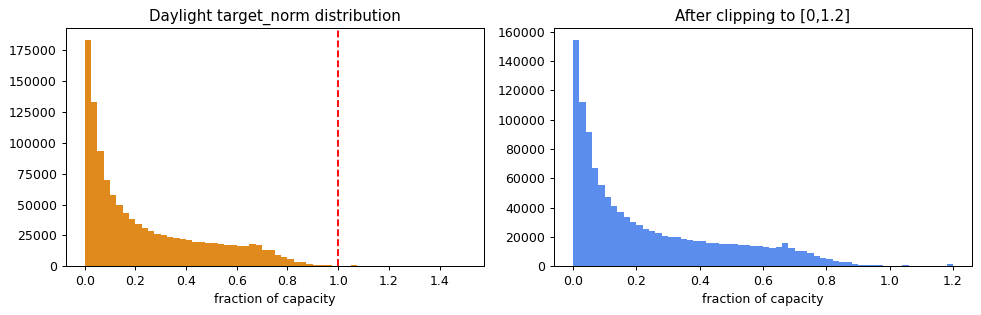

In [4]:
day = df[df.is_daylight & df.is_valid]
night = df[~df.is_daylight]
print("rows: total %d | daylight+valid %d (%.0f%%) | night %d (%.0f%%)" %
      (len(df), len(day), 100*len(day)/len(df), len(night), 100*len(night)/len(df)))
print("night target max (should be 0):", float(night.target_power_w.max()))
over = (day.target_norm>1.0).sum()
print("daylight target_norm >1.0 : %d (%.1f%%), max=%.2f" %
      (over, 100*over/len(day), day.target_norm.max()))
fig,ax=plt.subplots(1,2,figsize=(11,3.6))
ax[0].hist(day.target_norm, bins=60, color="#e08a1e"); ax[0].axvline(1.0,color="r",ls="--")
ax[0].set_title("Daylight target_norm distribution"); ax[0].set_xlabel("fraction of capacity")
ax[1].hist(day.target_norm.clip(0,1.2), bins=60, color="#5b8def")
ax[1].set_title("After clipping to [0,1.2]"); ax[1].set_xlabel("fraction of capacity")
plt.tight_layout(); plt.show()


## 3. Feature completeness and distributions

Every weather/physics feature should be populated for daylight rows. Any missing values
(possible at archive-chunk edges) must be dealt with before modelling.

NaN per feature (daylight+valid):
ghi_fc               0
dni_fc               0
dhi_fc               0
temp_fc              0
cloud_fc             0
wind_fc              0
poa_global_fc        0
clearsky_index_fc    0
sun_elevation        0
clearsky_ghi         0


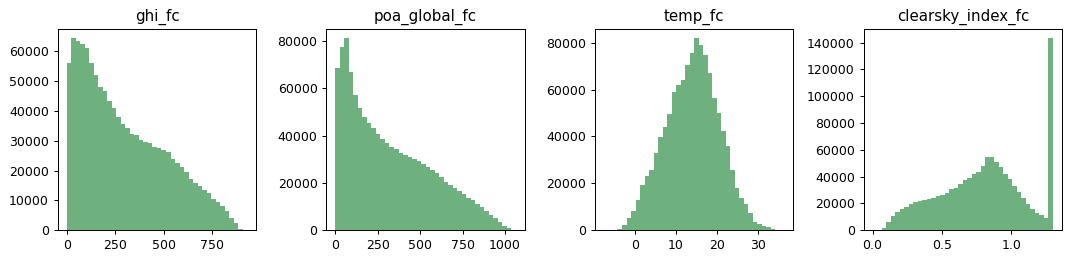

In [5]:
feat_cols = ["ghi_fc","dni_fc","dhi_fc","temp_fc","cloud_fc","wind_fc","poa_global_fc",
             "clearsky_index_fc","sun_elevation","clearsky_ghi"]
feat_cols = [c for c in feat_cols if c in df.columns]
na = day[feat_cols].isna().sum()
print("NaN per feature (daylight+valid):")
print(na.to_string())
show = [c for c in ["ghi_fc","poa_global_fc","temp_fc","clearsky_index_fc"] if c in day.columns]
fig,axes=plt.subplots(1,len(show),figsize=(3*len(show),3))
for ax,cc in zip(np.atleast_1d(axes),show):
    ax.hist(day[cc].dropna(), bins=40, color="#6fb07f"); ax.set_title(cc)
plt.tight_layout(); plt.show()


## 4. How well do features explain output? (physical sanity)

If the physics is right, plane-of-array irradiance (POA) should track output almost
linearly. The scatter and the correlation bar confirm which features carry signal - and
that POA/GHI dominate, exactly as expected.

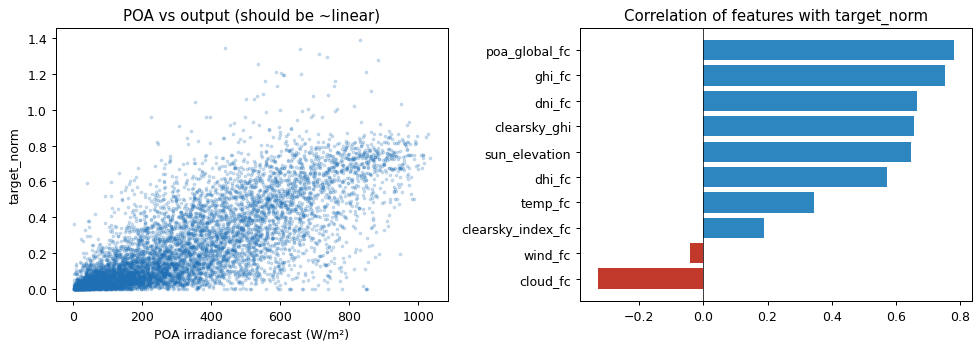

POA/GHI should top the chart; clear-sky index alone is a ratio so its *linear* correlation is low even though it is informative in combination.


In [6]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
s = day.sample(min(8000,len(day)), random_state=1)
ax[0].scatter(s.poa_global_fc, s.target_norm, s=4, alpha=0.2, color="#1f6fb5")
ax[0].set_xlabel("POA irradiance forecast (W/m²)"); ax[0].set_ylabel("target_norm")
ax[0].set_title("POA vs output (should be ~linear)")
corr = day[["target_norm"]+feat_cols].corr()["target_norm"].drop("target_norm").sort_values()
ax[1].barh(corr.index, corr.values, color=["#c0392b" if v<0 else "#2e86c1" for v in corr.values])
ax[1].set_title("Correlation of features with target_norm"); ax[1].axvline(0,color="k",lw=.6)
plt.tight_layout(); plt.show()
print("POA/GHI should top the chart; clear-sky index alone is a ratio so its *linear* "
      "correlation is low even though it is informative in combination.")


## 5. The weather-forecast ceiling

The day-ahead forecast (`*_fc`) differs from the best-estimate benchmark (`bench_*`).
That gap is the **irreducible weather error** your model inherits - a useful number to
report, because your model cannot beat the weather forecast it is given.

Mean |forecast GHI - benchmark GHI| (daylight): 32.6 W/m²


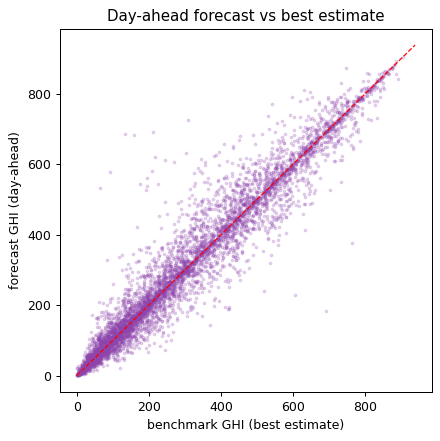

In [7]:
if "bench_ghi" in df.columns:
    d = day.dropna(subset=["ghi_fc","bench_ghi"])
    mae = (d.ghi_fc-d.bench_ghi).abs().mean()
    print("Mean |forecast GHI - benchmark GHI| (daylight): %.1f W/m²" % mae)
    fig,ax=plt.subplots(figsize=(5,5))
    s=d.sample(min(6000,len(d)),random_state=2)
    ax.scatter(s.bench_ghi,s.ghi_fc,s=4,alpha=0.2,color="#8e44ad")
    lim=[0,max(d.bench_ghi.max(),d.ghi_fc.max())]; ax.plot(lim,lim,"r--",lw=1)
    ax.set_xlabel("benchmark GHI (best estimate)"); ax.set_ylabel("forecast GHI (day-ahead)")
    ax.set_title("Day-ahead forecast vs best estimate"); plt.tight_layout(); plt.show()
else:
    print("No benchmark columns (FETCH_BENCHMARK was off).")


## 6. Preprocessing -> model-ready dataset

Now we turn the explored table into training data. The steps, each with a reason:

1. **Keep valid rows only** (`is_valid`) - drops long daytime gaps that were left missing.
2. **Train/evaluate on daylight** - night is a deterministic zero and would inflate scores.
   (We keep a `is_daylight` flag so night can be re-attached for full-day output.)
3. **Clip `target_norm` to [0, 1.2]** - removes non-physical spikes from capacity
   under-statement while keeping genuine mild over-production.
4. **Fill any residual feature NaNs** - forward/backward within system-time.
5. **Time-based split** - train on the earliest period, validate on the middle, test on
   the most recent, so evaluation mimics true forecasting (never shuffle time).

In [8]:
m = df[df.is_valid].copy()
m = m[m.is_daylight].copy()                       # daylight-only for training
m["target_norm"] = m["target_norm"].clip(0, 1.2)  # step 3
feat_all = [c for c in ["ghi_fc","dni_fc","dhi_fc","temp_fc","cloud_fc","wind_fc",
            "poa_global_fc","clearsky_index_fc","sun_elevation","sun_azimuth",
            "clearsky_ghi","hour_sin","hour_cos","doy_sin","doy_cos",
            "capacity_kwp","tilt_deg","azimuth_deg"] if c in m.columns]
m[feat_all] = (m.sort_values("timestamp").groupby("system_id")[feat_all]
                 .apply(lambda g: g.ffill().bfill()).reset_index(drop=True)) \
              if m[feat_all].isna().any().any() else m[feat_all]

# time-based split by quantiles of the date range
t = m["timestamp"]
q70, q85 = t.quantile(0.70), t.quantile(0.85)
m["split"] = np.where(t<=q70,"train", np.where(t<=q85,"val","test"))
print("split boundaries:  train <= %s  |  val <= %s  |  test after" %
      (q70.date(), q85.date()))
print(m["split"].value_counts().to_string())
print("\nmodel-ready columns:", ["system_id","timestamp","target_norm"]+feat_all+["split"])

out = m[["system_id","timestamp","target_norm","target_power_w","is_daylight"]+feat_all+["split"]]
Path("pv_features").mkdir(exist_ok=True)
out.to_csv("pv_features/model_ready.csv", index=False)
print("\nsaved pv_features/model_ready.csv:", out.shape)


split boundaries:  train <= 2025-09-14  |  val <= 2026-02-15  |  test after
split
train    817418
val      175154
test     175138

model-ready columns: ['system_id', 'timestamp', 'target_norm', 'ghi_fc', 'dni_fc', 'dhi_fc', 'temp_fc', 'cloud_fc', 'wind_fc', 'poa_global_fc', 'clearsky_index_fc', 'sun_elevation', 'sun_azimuth', 'clearsky_ghi', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos', 'capacity_kwp', 'tilt_deg', 'azimuth_deg', 'split']

saved pv_features/model_ready.csv: (1167710, 24)


## 7. Summary & what's next

- The feature table is physically coherent: POA/GHI dominate the correlation with output,
  night is a clean zero, and the day-ahead forecast carries a measurable (irreducible)
  error versus the best estimate.
- Preprocessing produced `model_ready.csv`: valid daylight rows, target clipped to a
  physical range, features gap-filled, and a **time-ordered train/val/test split**.

**Next (modelling):** start with baselines - *persistence* (tomorrow ≈ a recent analog)
and *clear-sky* (output ∝ clear-sky/POA) - then a gradient-boosted model on these
features, scored on daylight rows with a **skill score** against the baselines.

**Alternative split for generalisation:** instead of (or alongside) the time split,
train on one set of systems and test on unseen systems (leave-systems-out) to measure how
well the model transfers to a new household - the core question for a fleet-wide forecaster.
